In [1]:
# library digunakan untuk manipulasi dan analisis data tabular
import pandas as pd
import numpy as np

# library digunakan untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# library digunakan untuk membangun model Machine Learning Decision Tree dan evaluasi
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

In [2]:
# library digunakan untuk memuat dataset CSV ke dalam pandas DataFrame
df = pd.read_csv('Mental_Health_and_Social_Media_Balance_Dataset.csv')

# Menampilkan 5 baris pertama dari dataset untuk memeriksa struktur data
print("5 Data Teratas:")
display(df.head())

5 Data Teratas:


,User_ID,Age,Gender,Daily_Screen_Time(hrs),Sleep_Quality(1-10),Stress_Level(1-10),Days_Without_Social_Media,Exercise_Frequency(week),Social_Media_Platform,Happiness_Index(1-10)
0,U001,44,Male,3.1,7.0,6.0,2.0,5.0,Facebook,10.0
1,U002,30,Other,5.1,7.0,8.0,5.0,3.0,LinkedIn,10.0
2,U003,23,Other,7.4,6.0,7.0,1.0,3.0,YouTube,6.0
3,U004,36,Female,5.7,7.0,8.0,1.0,1.0,TikTok,8.0
4,U005,34,Female,7.0,4.0,7.0,5.0,1.0,X (Twitter),8.0


In [3]:
df = pd.read_csv('Mental_Health_and_Social_Media_Balance_Dataset.csv')

# 2. Menampilkan 5 baris pertama data
print("--- 5 Data Teratas ---")
display(df.head())

# 3. Mengecek informasi kolom & tipe data
print("\n--- Informasi Dataset ---")
df.info()

# 4. Mengecek jumlah missing values (data kosong)
print("\n--- Jumlah Missing Values ---")
print(df.isnull().sum())

# 5. Ringkasan statistik deskriptif
print("\n--- Statistik Deskriptif ---")
display(df.describe())

--- 5 Data Teratas ---


,User_ID,Age,Gender,Daily_Screen_Time(hrs),Sleep_Quality(1-10),Stress_Level(1-10),Days_Without_Social_Media,Exercise_Frequency(week),Social_Media_Platform,Happiness_Index(1-10)
0,U001,44,Male,3.1,7.0,6.0,2.0,5.0,Facebook,10.0
1,U002,30,Other,5.1,7.0,8.0,5.0,3.0,LinkedIn,10.0
2,U003,23,Other,7.4,6.0,7.0,1.0,3.0,YouTube,6.0
3,U004,36,Female,5.7,7.0,8.0,1.0,1.0,TikTok,8.0
4,U005,34,Female,7.0,4.0,7.0,5.0,1.0,X (Twitter),8.0



--- Informasi Dataset ---
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   User_ID                    500 non-null    str    
 1   Age                        500 non-null    int64  
 2   Gender                     500 non-null    str    
 3   Daily_Screen_Time(hrs)     500 non-null    float64
 4   Sleep_Quality(1-10)        500 non-null    float64
 5   Stress_Level(1-10)         500 non-null    float64
 6   Days_Without_Social_Media  500 non-null    float64
 7   Exercise_Frequency(week)   500 non-null    float64
 8   Social_Media_Platform      500 non-null    str    
 9   Happiness_Index(1-10)      500 non-null    float64
dtypes: float64(6), int64(1), str(3)
memory usage: 39.2 KB

--- Jumlah Missing Values ---
User_ID                      0
Age                          0
Gender                       0
Daily_Screen_Time(hrs)  

,Age,Daily_Screen_Time(hrs),Sleep_Quality(1-10),Stress_Level(1-10),Days_Without_Social_Media,Exercise_Frequency(week),Happiness_Index(1-10)
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,32.988000,5.530000,6.304000,6.618000,3.134000,2.448000,8.376000
std,9.960637,1.734877,1.529792,1.542996,1.858751,1.428067,1.524228
min,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,4.000000
25%,24.000000,4.300000,5.000000,6.000000,2.000000,1.000000,7.000000
50%,34.000000,5.600000,6.000000,7.000000,3.000000,2.000000,9.000000
75%,41.000000,6.700000,7.000000,8.000000,5.000000,3.000000,10.000000
max,49.000000,10.800000,10.000000,10.000000,9.000000,7.000000,10.000000


In [4]:
# Pre-processing: Mengubah nilai kontinu 'Happiness_Index' (skala 1-10) menjadi kategori diskrit (Rendah, Sedang, Tinggi)
# karena tugas ini adalah klasifikasi menggunakan Decision Tree
bins = [0, 6, 8, 10]
labels = ['Rendah', 'Sedang', 'Tinggi']
df['Happiness_Category'] = pd.cut(df['Happiness_Index(1-10)'], bins=bins, labels=labels)

# Memeriksa distribusi kelas target yang baru
print("Distribusi Kelas Happiness Category:")
print(df['Happiness_Category'].value_counts())

Distribusi Kelas Happiness Category:
Happiness_Category
Tinggi    256
Sedang    182
Rendah     62
Name: count, dtype: int64


In [5]:
# Pre-processing: Mengubah fitur kategorikal (Gender & Social_Media_Platform) menjadi numerik menggunakan One-Hot Encoding
df_processed = pd.get_dummies(df, columns=['Gender', 'Social_Media_Platform'], drop_first=True)

# Menentukan variabel independen (X) dan variabel dependen/target (y)
X = df_processed.drop(columns=['User_ID', 'Happiness_Index(1-10)', 'Happiness_Category'])
y = df_processed['Happiness_Category']

print("Fitur yang digunakan:", list(X.columns))

Fitur yang digunakan: ['Age', 'Daily_Screen_Time(hrs)', 'Sleep_Quality(1-10)', 'Stress_Level(1-10)', 'Days_Without_Social_Media', 'Exercise_Frequency(week)', 'Gender_Male', 'Gender_Other', 'Social_Media_Platform_Instagram', 'Social_Media_Platform_LinkedIn', 'Social_Media_Platform_TikTok', 'Social_Media_Platform_X (Twitter)', 'Social_Media_Platform_YouTube']


In [6]:
# Membagi dataset menjadi data latih (80%) dan data uji (20%) untuk evaluasi model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Jumlah data latih: {X_train.shape[0]} baris")
print(f"Jumlah data uji: {X_test.shape[0]} baris")

Jumlah data latih: 400 baris
Jumlah data uji: 100 baris


In [7]:
# Inisialisasi dan pelatihan model Decision Tree Classifier
clf = DecisionTreeClassifier(criterion='gini', random_state=42, max_depth=4)
clf.fit(X_train, y_train)

print("Model Decision Tree berhasil dilatih!")

Model Decision Tree berhasil dilatih!


In [8]:
# Melakukan prediksi dan mengevaluasi akurasi model
y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Akurasi Model Decision Tree: {accuracy * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Akurasi Model Decision Tree: 71.00%

Classification Report:
              precision    recall  f1-score   support

      Rendah       0.71      0.36      0.48        14
      Sedang       0.53      0.81      0.64        32
      Tinggi       0.91      0.74      0.82        54

    accuracy                           0.71       100
   macro avg       0.72      0.64      0.64       100
weighted avg       0.76      0.71      0.71       100



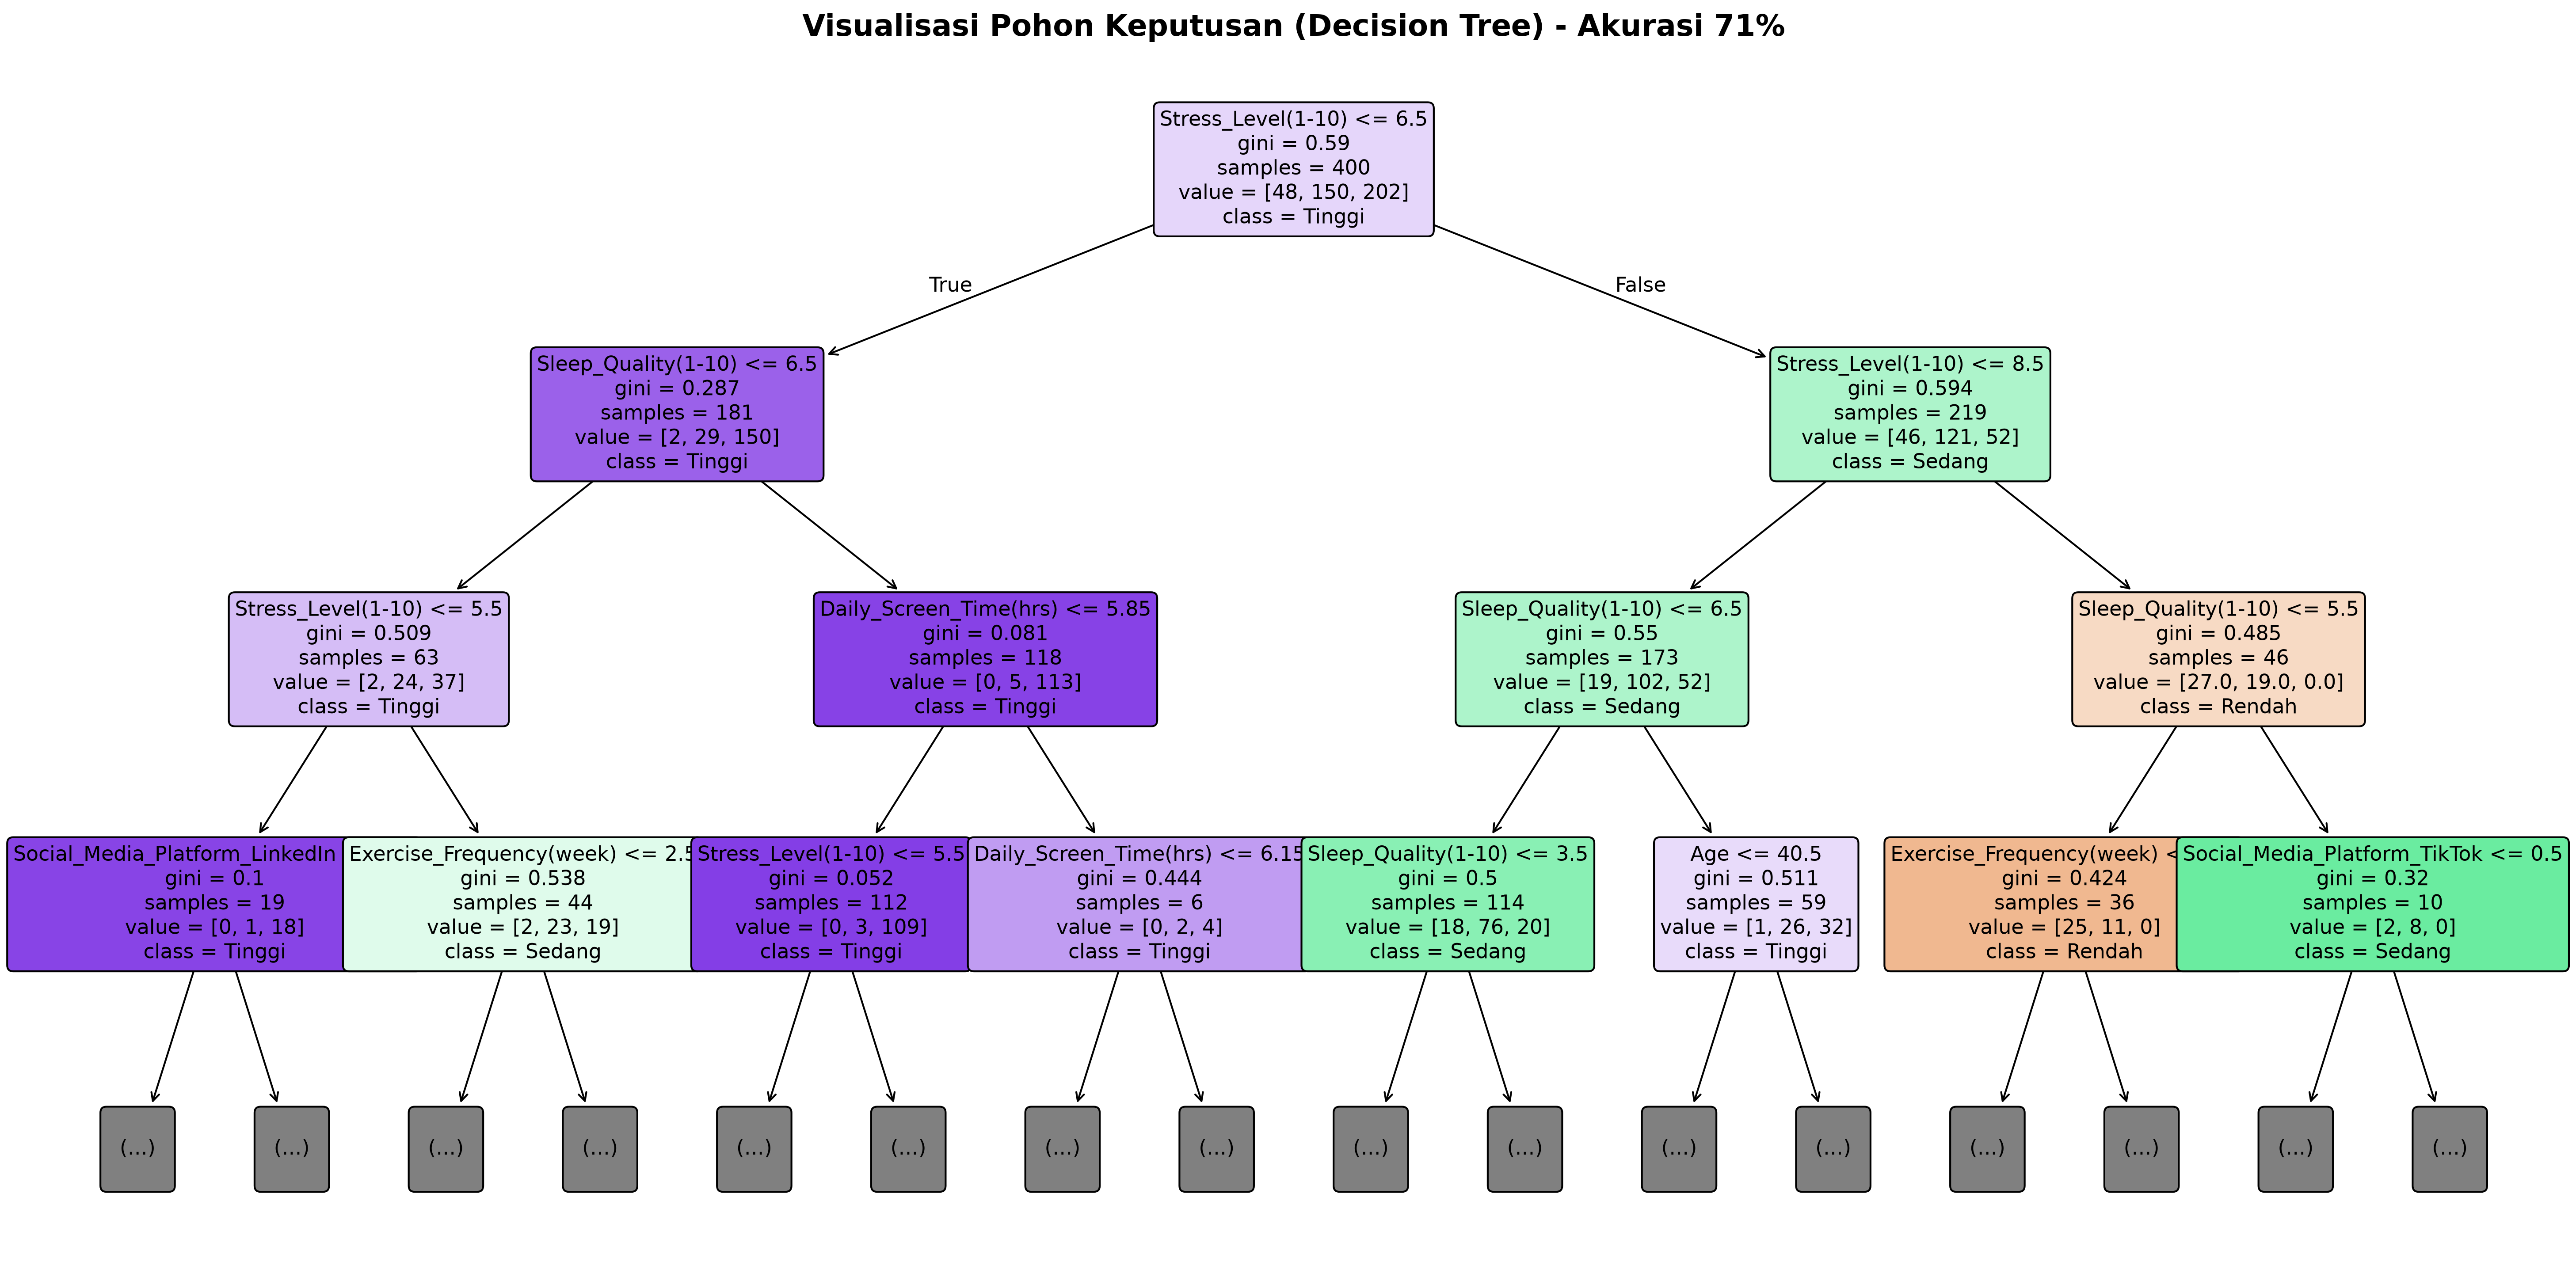

In [9]:
# Visualisasi Decision Tree
plt.figure(figsize=(24, 12), dpi=300)
plot_tree(
    clf, 
    max_depth=3, 
    feature_names=list(X.columns), 
    class_names=clf.classes_, 
    filled=True, 
    rounded=True,
    fontsize=11
)
plt.title("Visualisasi Pohon Keputusan (Decision Tree) - Akurasi 71%", fontsize=16, fontweight='bold')
plt.show()

In [10]:
# 1. Menampilkan Decision Tree dalam bentuk Aturan Teks (Decision Rules)
from sklearn.tree import export_text

tree_rules = export_text(clf, feature_names=list(X.columns))
print("=== ATURAN KEPUTUSAN (DECISION RULES) SEBAGAI TEKS ===")
print(tree_rules)

# %%
# 2. Menampilkan tingkat pengaruh (Feature Importance) dari setiap aspek/kolom
feature_importance = pd.DataFrame({
    'Fitur / Aspek': X.columns,
    'Tingkat Pengaruh': clf.feature_importances_
}).sort_values(by='Tingkat Pengaruh', ascending=False)

print("\n=== FAKTOR UTAMA YANG MEMENGARUHI MODEL ===")
print(feature_importance.to_string(index=False))

# %%
# 3. Analisis Deskriptif: Platform Sosmed, Usia, dan Gender dari Dataset
print("\n=== ANALISIS DESKRIPTIF ASPEK DATASET ===")
print("1. Distribusi Penggunaan Platform Media Sosial:")
print(df['Social_Media_Platform'].value_counts())

print("\n2. Ringkasan Statistik Usia (Age):")
print(f"   - Usia Rata-rata: {df['Age'].mean():.1f} tahun")
print(f"   - Usia Minimum : {df['Age'].min()} tahun")
print(f"   - Usia Maksimum : {df['Age'].max()} tahun")

print("\n3. Distribusi Gender:")
print(df['Gender'].value_counts())

=== ATURAN KEPUTUSAN (DECISION RULES) SEBAGAI TEKS ===
|--- Stress_Level(1-10) <= 6.50
|   |--- Sleep_Quality(1-10) <= 6.50
|   |   |--- Stress_Level(1-10) <= 5.50
|   |   |   |--- Social_Media_Platform_LinkedIn <= 0.50
|   |   |   |   |--- class: Tinggi
|   |   |   |--- Social_Media_Platform_LinkedIn >  0.50
|   |   |   |   |--- class: Sedang
|   |   |--- Stress_Level(1-10) >  5.50
|   |   |   |--- Exercise_Frequency(week) <= 2.50
|   |   |   |   |--- class: Tinggi
|   |   |   |--- Exercise_Frequency(week) >  2.50
|   |   |   |   |--- class: Sedang
|   |--- Sleep_Quality(1-10) >  6.50
|   |   |--- Daily_Screen_Time(hrs) <= 5.85
|   |   |   |--- Stress_Level(1-10) <= 5.50
|   |   |   |   |--- class: Tinggi
|   |   |   |--- Stress_Level(1-10) >  5.50
|   |   |   |   |--- class: Tinggi
|   |   |--- Daily_Screen_Time(hrs) >  5.85
|   |   |   |--- Daily_Screen_Time(hrs) <= 6.15
|   |   |   |   |--- class: Sedang
|   |   |   |--- Daily_Screen_Time(hrs) >  6.15
|   |   |   |   |--- class: Ti